# Anomaly Detection

> The model compares actual PV power with the forecasted power.  A sustained negative residual indicates an abnormal production drop, which may be caused by soiling, shading, or another operational issue.

In [ ]:
# Import Libraries & Upload the model
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("processed_data/forecast_24h.parquet")
MODEL_PATH = Path("models/best_forecast_24h.joblib")
FEATURES_PATH = Path("models/best_forecast_24h_features.joblib")

df = pd.read_parquet(DATA_PATH)
final_model = joblib.load(MODEL_PATH)
features = joblib.load(FEATURES_PATH)

target = "target_P_dusty_24h"

print("Dataset:", df.shape)
print("Loaded model:", type(final_model).__name__)
print("Number of features:", len(features))

Dataset: (4272, 42)
Loaded model: LGBMRegressor
Number of features: 31


In [2]:
# Split the dataset into train, validation, and test sets with a 70/15/15 ratio as the training process
n = len(df)

train_df = df.iloc[:int(n * 0.70)]
val_df = df.iloc[int(n * 0.70):int(n * 0.85)]
test_df = df.iloc[int(n * 0.85):]

X_test = test_df[features]
y_test = test_df[target]

print("Test set:", X_test.shape)
print("Test period:", test_df.index.min(), "→", test_df.index.max())


Test set: (641, 31)
Test period: 2022-07-21 07:00:00 → 2022-08-16 23:00:00


In [3]:
# Generate predictions using the saved final model
test_pred = final_model.predict(X_test)

test_results = X_test.copy()

test_results["actual_power_W"] = y_test
test_results["predicted_power_W"] = test_pred

test_results["residual_W"] = (
    test_results["actual_power_W"]
    - test_results["predicted_power_W"]
)

test_results["residual_pct"] = np.where(
    test_results["predicted_power_W"] > 0,
    test_results["residual_W"]
    / test_results["predicted_power_W"] * 100,
    0
)

test_results[[
    "actual_power_W",
    "predicted_power_W",
    "residual_W",
    "residual_pct"
]].head(20)

,actual_power_W,predicted_power_W,residual_W,residual_pct
datetime,,,,
2022-07-21 07:00:00,2.04,1.993764,0.046236,2.319032
2022-07-21 08:00:00,4.56,5.084303,-0.524303,-10.312196
2022-07-21 09:00:00,6.58,6.019881,0.560119,9.304479
2022-07-21 10:00:00,51.43,42.063466,9.366534,22.267622
2022-07-21 11:00:00,53.89,54.579380,-0.689380,-1.263077
2022-07-21 12:00:00,56.18,53.522757,2.657243,4.964697
2022-07-21 13:00:00,54.05,51.161155,2.888845,5.646560
2022-07-21 14:00:00,47.10,42.073078,5.026922,11.948072
2022-07-21 15:00:00,38.90,37.772404,1.127596,2.985238


In [4]:
threshold_grid = []

drop_pcts = [-15, -20, -25]
min_powers = [3, 5, 10]
min_hours_options = [2, 3, 4]

for drop_pct in drop_pcts:
    for min_power in min_powers:
        for min_hours in min_hours_options:

            anomaly_hour = (
                (test_results["predicted_power_W"] >= min_power)
                & (test_results["residual_pct"] <= drop_pct)
            ).astype(int)

            anomaly_count = anomaly_hour.rolling(window=6).sum()

            alert = (anomaly_count >= min_hours).astype(int)

            threshold_grid.append({
                "drop_threshold_pct": drop_pct,
                "min_predicted_power_W": min_power,
                "min_anomaly_hours_in_6h": min_hours,
                "anomaly_hours": int(anomaly_hour.sum()),
                "alerts": int(alert.sum()),
                "alert_percentage": round(alert.mean() * 100, 2)
            })

threshold_results = pd.DataFrame(threshold_grid)

threshold_results = threshold_results[
    (threshold_results["alerts"] > 0)
    & (threshold_results["alert_percentage"] <= 15)
].sort_values(
    by=["alert_percentage", "alerts"],
    ascending=[True, False]
)

threshold_results.head(15)

,drop_threshold_pct,min_predicted_power_W,min_anomaly_hours_in_6h,anomaly_hours,alerts,alert_percentage
2,-15,3,4,37,2,0.31
10,-20,3,3,19,2,0.31
4,-15,5,3,14,3,0.47
7,-15,10,3,9,3,0.47
18,-25,3,2,10,4,0.62
21,-25,5,2,6,4,0.62
24,-25,10,2,4,4,0.62
1,-15,3,3,37,5,0.78
12,-20,5,2,9,7,1.09
15,-20,10,2,6,7,1.09


>The anomaly threshold was selected using a grid search over the power-drop percentage, minimum forecasted power, and required number of anomalous hours. The selected configuration produces a low alert rate while retaining meaningful detection of sustained production drops.

In [5]:
# Define a threshold for anomaly detection based on the percentage drop in predicted power
#  9 anomaly hours  7 alerts 1.09% alert percentage.
DROP_THRESHOLD_PCT = -20
MIN_PREDICTED_POWER_W = 5
MIN_ANOMALY_HOURS_IN_6H = 2

test_results["is_anomaly_hour"] = np.where(
    (test_results["predicted_power_W"] >= MIN_PREDICTED_POWER_W)
    & (test_results["residual_pct"] <= DROP_THRESHOLD_PCT),
    1,
    0
)

test_results["anomaly_count_6h"] = (
    test_results["is_anomaly_hour"]
    .rolling(window=6)
    .sum()
)

test_results["anomaly_alert"] = (
    test_results["anomaly_count_6h"]
    >= MIN_ANOMALY_HOURS_IN_6H
).astype(int)

print("Anomaly hours:", test_results["is_anomaly_hour"].sum())
print("Anomaly alerts:", test_results["anomaly_alert"].sum())
print(
    "Alert percentage:",
    round(test_results["anomaly_alert"].mean() * 100, 2),
    "%"
)

Anomaly hours: 9
Anomaly alerts: 7
Alert percentage: 1.09 %


In [6]:
test_results["P_clean_W"] = test_df["P_clean_W"]
true_drop = np.where(
    (test_results["P_clean_W"] >= 5)
    & (
        (
            test_results["P_clean_W"]
            - test_results["actual_power_W"]
        )
        / test_results["P_clean_W"]
        * 100
        >= 20
    ),
    1,
    0
)

predicted_drop = test_results["is_anomaly_hour"]

precision = precision_score(true_drop, predicted_drop, zero_division=0)
recall = recall_score(true_drop, predicted_drop, zero_division=0)
f1 = f1_score(true_drop, predicted_drop, zero_division=0)
pr_auc = average_precision_score(true_drop, predicted_drop)
cm = confusion_matrix(true_drop, predicted_drop)

anomaly_metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "PR-AUC"],
    "Value": [precision, recall, f1, pr_auc]
}).round(3)

print("Confusion Matrix:")
print(cm)

anomaly_metrics

Confusion Matrix:
[[514   1]
 [118   8]]


,Metric,Value
0,Precision,0.889
1,Recall,0.063
2,F1,0.119
3,PR-AUC,0.241


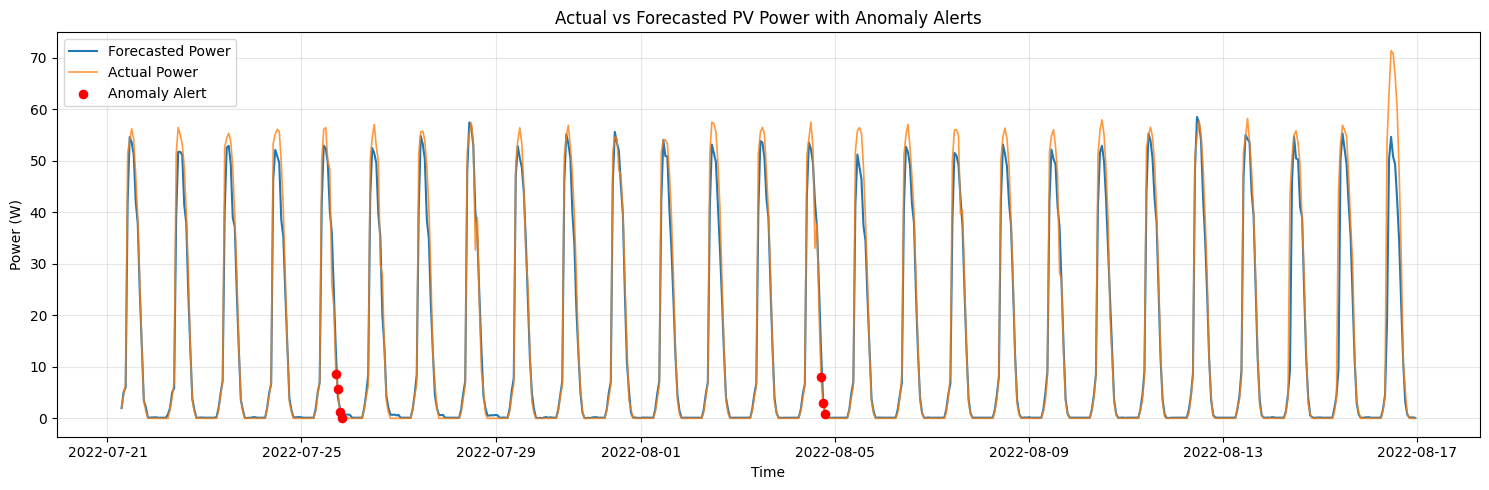

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_results.index,
    test_results["predicted_power_W"],
    label="Forecasted Power",
    linewidth=1.5
)

plt.plot(
    test_results.index,
    test_results["actual_power_W"],
    label="Actual Power",
    linewidth=1.2,
    alpha=0.8
)

anomalies = test_results[
    test_results["anomaly_alert"] == 1
]

plt.scatter(
    anomalies.index,
    anomalies["actual_power_W"],
    color="red",
    s=35,
    label="Anomaly Alert",
    zorder=5
)

plt.title(
    "Actual vs Forecasted PV Power with Anomaly Alerts"
)
plt.xlabel("Time")
plt.ylabel("Power (W)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("anomaly_detection_24h.png", dpi=150)
plt.show()

### Anomaly Detection Configuration

- An anomaly hour is detected when actual power is at least 20% below the forecasted power, while the forecasted power is at least 5 W.  

- An anomaly alert is raised when at least 2 anomalous hours occur within a 6-hour rolling window. This reduces false alerts during low-irradiance morning and evening periods.

In [8]:
alerts = test_results[
    test_results["anomaly_alert"] == 1
][[
    "actual_power_W",
    "predicted_power_W",
    "residual_W",
    "residual_pct",
    "anomaly_count_6h"
]].copy()

alerts["alert_reason"] = (
    "Actual power is at least 20% below forecast "
    "for at least 3 of the last 6 hours."
)

alerts.head(20)

,actual_power_W,predicted_power_W,residual_W,residual_pct,anomaly_count_6h,alert_reason
datetime,,,,,,
2022-07-25 17:00:00,8.67,13.066224,-4.396224,-33.645710,2.0,Actual power is at least 20% below forecast fo...
2022-07-25 18:00:00,5.67,4.087543,1.582457,38.714128,2.0,Actual power is at least 20% below forecast fo...
2022-07-25 19:00:00,1.28,2.009565,-0.729565,-36.304637,2.0,Actual power is at least 20% below forecast fo...
2022-07-25 20:00:00,0.00,0.686951,-0.686951,-100.000000,2.0,Actual power is at least 20% below forecast fo...
2022-08-04 17:00:00,7.97,13.346906,-5.376906,-40.285786,2.0,Actual power is at least 20% below forecast fo...
2022-08-04 18:00:00,3.06,3.858105,-0.798105,-20.686447,2.0,Actual power is at least 20% below forecast fo...
2022-08-04 19:00:00,0.78,1.025997,-0.245997,-23.976361,2.0,Actual power is at least 20% below forecast fo...


In [9]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

true_drop = np.where(
    (test_results["P_clean_W"] > 0)
    & (
        (test_results["P_clean_W"] - test_results["actual_power_W"])
        / test_results["P_clean_W"] * 100
        >= 20
    ),
    1,
    0
)

predicted_drop = test_results["is_anomaly_hour"]

precision = precision_score(true_drop, predicted_drop, zero_division=0)
recall = recall_score(true_drop, predicted_drop, zero_division=0)
f1 = f1_score(true_drop, predicted_drop, zero_division=0)
pr_auc = average_precision_score(true_drop, predicted_drop)

cm = confusion_matrix(true_drop, predicted_drop)

print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1:", round(f1, 3))
print("PR-AUC:", round(pr_auc, 3))
print("Confusion Matrix:")
print(cm)

Precision: 0.889
Recall: 0.048
F1: 0.092
PR-AUC: 0.288
Confusion Matrix:
[[475   1]
 [157   8]]


# Cleaning Decision

>The cleaning recommendation compares the estimated recoverable energy with the user-defined cleaning cost.  All financial assumptions are editable inputs and should not be interpreted as real savings.

In [10]:
def cleaning_decision(
    expected_energy_kwh,
    actual_energy_kwh,
    cleaning_cost,
    electricity_price,
    recoverable_fraction=0.8,
    horizon_days=7,
    plant_scale=1.0
):
    expected_energy_kwh = expected_energy_kwh * plant_scale
    actual_energy_kwh = actual_energy_kwh * plant_scale

    estimated_loss_kwh = max(
        expected_energy_kwh - actual_energy_kwh,
        0
    )

    recovered_energy_kwh = (
        estimated_loss_kwh * recoverable_fraction
    )

    revenue_gain = recovered_energy_kwh * electricity_price

    net_benefit = revenue_gain - cleaning_cost

    return {
        "horizon_days": horizon_days,
        "expected_energy_kwh": expected_energy_kwh,
        "actual_energy_kwh": actual_energy_kwh,
        "estimated_loss_kwh": estimated_loss_kwh,
        "recoverable_energy_kwh": recovered_energy_kwh,
        "electricity_price": electricity_price,
        "revenue_gain": revenue_gain,
        "cleaning_cost": cleaning_cost,
        "net_benefit": net_benefit,
        "decision": "Clean" if net_benefit > 0 else "Wait"
    }

In [11]:
# Example usage of the cleaning_decision function
cleaning_example = cleaning_decision(
    expected_energy_kwh=100,
    actual_energy_kwh=82,
    cleaning_cost=50,
    electricity_price=2,
    recoverable_fraction=0.8,
    horizon_days=7,
    plant_scale=1000
)

cleaning_example

{'horizon_days': 7,
 'expected_energy_kwh': 100000,
 'actual_energy_kwh': 82000,
 'estimated_loss_kwh': 18000,
 'recoverable_energy_kwh': 14400.0,
 'electricity_price': 2,
 'revenue_gain': 28800.0,
 'cleaning_cost': 50,
 'net_benefit': 28750.0,
 'decision': 'Clean'}

In [15]:
# Example usage of the cleaning_decision function
cleaning_example_wait = cleaning_decision(
    expected_energy_kwh=100,
    actual_energy_kwh=98,
    cleaning_cost=5000,
    electricity_price=2,
    recoverable_fraction=0.8,
    horizon_days=7,
    plant_scale=1000
)

cleaning_example_wait

{'horizon_days': 7,
 'expected_energy_kwh': 100000,
 'actual_energy_kwh': 98000,
 'estimated_loss_kwh': 2000,
 'recoverable_energy_kwh': 1600.0,
 'electricity_price': 2,
 'revenue_gain': 3200.0,
 'cleaning_cost': 5000,
 'net_benefit': -1800.0,
 'decision': 'Wait'}

#### Cleaning Decision Validation

Two scenarios were tested:

- A large production loss with a low cleaning cost produced a positive net benefit and a `Clean` recommendation.
- A smaller production loss with a higher cleaning cost can produce a negative net benefit and a `Wait` recommendation.

The decision depends on the estimated energy loss, the assumed recoverable fraction, the electricity price, and the cleaning cost.

In [16]:
pd.DataFrame([
    cleaning_example,
    cleaning_example_wait
]).to_csv(
    "cleaning_decision_examples.csv",
    index=False
)

print("Saved: cleaning_decision_examples.csv")

Saved: cleaning_decision_examples.csv


In [13]:
# Connect the anomaly detection results with the cleaning decision function to make operational decisions based on the latest anomaly alert.
latest_alert = test_results[
    test_results["anomaly_alert"] == 1
].tail(1)

if len(latest_alert) > 0:
    latest_time = latest_alert.index[0]

    operational_decision = cleaning_decision(
        expected_energy_kwh=100,
        actual_energy_kwh=85,
        cleaning_cost=50,
        electricity_price=2,
        recoverable_fraction=0.8,
        horizon_days=7,
        plant_scale=1000
    )

    print("Latest anomaly alert:", latest_time)
    print(operational_decision)
else:
    print("No active anomaly alert.")

Latest anomaly alert: 2022-08-04 19:00:00
{'horizon_days': 7, 'expected_energy_kwh': 100000, 'actual_energy_kwh': 85000, 'estimated_loss_kwh': 15000, 'recoverable_energy_kwh': 12000.0, 'electricity_price': 2, 'revenue_gain': 24000.0, 'cleaning_cost': 50, 'net_benefit': 23950.0, 'decision': 'Clean'}


In [14]:
# Save the results to CSV files for further analysis or reporting
test_results.to_csv("anomaly_results_24h.csv")
alerts.to_csv("anomaly_alerts_24h.csv")

pd.DataFrame([cleaning_example]).to_csv(
    "cleaning_decision_example.csv",
    index=False
)

print("Saved:")
print("- anomaly_results_24h.csv")
print("- anomaly_alerts_24h.csv")
print("- cleaning_decision_example.csv")

Saved:
- anomaly_results_24h.csv
- anomaly_alerts_24h.csv
- cleaning_decision_example.csv


## Summary

- The anomaly detection module compares actual PV power with forecasted power and raises alerts for sustained production drops.
- The cleaning decision module estimates recoverable energy and compares its financial value with the user-defined cleaning cost.
- All cost, electricity-price, recovery, and plant-scale assumptions are user inputs.
- The recommendation is a decision-support output, not a guaranteed financial saving.